In [65]:
import joblib
from matplotlib import pyplot as plt
import json
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, accuracy_score, \
    average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix
)



In [1]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent
data_path = project_root / "data" / "interim" / "modeling_dataset.parquet"

data = pd.read_parquet(data_path)

train_data = data.query("split == 'train'").drop(columns="split").copy()
validation_data = data.query("split == 'validation'").drop(columns="split").copy()
test_data = data.query("split == 'test'").drop(columns="split").copy()

In [5]:
groups_train = train_data["patient_nbr"].copy()
groups_validation = validation_data["patient_nbr"].copy()
groups_test = test_data["patient_nbr"].copy()

In [7]:
target_column = "target_30d"

excluded_features = [
    "target_30d",
    "readmitted",
    "encounter_id",
    "patient_nbr",
    "examide",
    "citoglipton",
]

In [8]:
X_train = train_data.drop(columns=excluded_features)
y_train = train_data[target_column].copy()

X_validation = validation_data.drop(columns=excluded_features)
y_validation = validation_data[target_column].copy()

X_test = test_data.drop(columns=excluded_features)
y_test = test_data[target_column].copy()

In [9]:
coded_categorical_features = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
]

for frame in [X_train, X_validation, X_test]:
    frame[coded_categorical_features] = (
        frame[coded_categorical_features].astype("string")
    )

In [12]:
numeric_features = (
    X_train
    .select_dtypes(include="number")
    .columns
    .tolist()
)

categorical_features = (
    X_train
    .select_dtypes(exclude="number")
    .columns
    .tolist()
)


In [14]:
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_preprocessor = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="constant", fill_value="Unknown"),
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore"),
    ),
])
preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ],
    remainder="drop",
)

In [18]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

fold_summary = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_train, y_train, groups=groups_train),
    start=1,
):
    fold_train_patients = set(groups_train.iloc[train_idx])
    fold_valid_patients = set(groups_train.iloc[valid_idx])

    fold_summary.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "valid_rows": len(valid_idx),
        "valid_patients": len(fold_valid_patients),
        "target_rate_pct": y_train.iloc[valid_idx].mean() * 100,
    })

fold_summary = pd.DataFrame(fold_summary)
fold_summary["target_rate_pct"] = fold_summary["target_rate_pct"].round(2)

fold_summary

,fold,train_rows,valid_rows,valid_patients,target_rate_pct
0,1,55613,13906,9833,11.39
1,2,55617,13902,9776,11.38
2,3,55615,13904,9821,11.39
3,4,55614,13905,9753,11.39
4,5,55617,13902,9810,11.39


In [31]:
dummy_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DummyClassifier(strategy="most_frequent")),
])


logistic_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            solver="liblinear",
            random_state=42,
        ),
    ),
])

blogistic_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            solver="liblinear",
            random_state=42,
        ),
    ),
])


In [33]:
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": make_scorer(recall_score),
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}


models = {
    "Dummy": dummy_pipeline,
    "Logistic": logistic_pipeline,
    "Logistic balanced": blogistic_pipeline,
}

cv_results = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )

    result = {"model": model_name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        result[f"{metric}_mean"] = values.mean()
        result[f"{metric}_std"] = values.std()

    cv_results.append(result)

cv_results = pd.DataFrame(cv_results).set_index("model").round(3)
cv_results

,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std
model,,,,,,,,,,
Dummy,0.500,0.000,0.114,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Logistic,0.649,0.007,0.208,0.008,0.022,0.003,0.447,0.018,0.042,0.005
Logistic balanced,0.646,0.008,0.206,0.008,0.539,0.016,0.175,0.003,0.264,0.006


Обычная и сбалансированная логистические регрессии показывают сопоставимые ROC-AUC и PR-AUC. Оставляем классическую регрессию

In [29]:
selected_model = clone(logistic_pipeline)
selected_model.fit(X_train, y_train)

validation_probability = selected_model.predict_proba(
    X_validation
)[:, 1]

validation_prediction = selected_model.predict(
    X_validation
)

In [37]:
precision, recall, thresholds = precision_recall_curve(
    y_validation,
    validation_probability,
)

threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision[:-1],
    "recall": recall[:-1],
})

threshold_results["f1"] = (
    2
    * threshold_results["precision"]
    * threshold_results["recall"]
    / (
        threshold_results["precision"]
        + threshold_results["recall"]
        + 1e-10
    )
)

threshold_results.sort_values(
    "f1",
    ascending=False,
).head(10)

,threshold,precision,recall,f1
11432,0.144118,0.212992,0.425862,0.283962
11431,0.144110,0.212931,0.425862,0.283908
11346,0.142481,0.211220,0.432759,0.283883
11430,0.144074,0.212870,0.425862,0.283854
11317,0.142078,0.210629,0.435057,0.283840
11345,0.142481,0.211161,0.432759,0.283830
11429,0.144050,0.212809,0.425862,0.283799
11316,0.142047,0.210570,0.435057,0.283786
11344,0.142473,0.211102,0.432759,0.283776
11428,0.144047,0.212748,0.425862,0.283745


In [42]:
best_threshold_result = threshold_results.loc[threshold_results["f1"].idxmax()]
best_threshold = best_threshold_result["threshold"]

print(f"Порог:    {best_threshold:.4f}")
print(f"Precision: {best_threshold_result['precision']:.3f}")
print(f"Recall:    {best_threshold_result['recall']:.3f}")
print(f"F1:        {best_threshold_result['f1']:.3f}")

Порог:    0.1441
Precision: 0.213
Recall:    0.426
F1:        0.284


              precision    recall  f1-score   support

           0      0.913     0.792     0.848     13171
           1      0.213     0.426     0.284      1740

    accuracy                          0.749     14911
   macro avg      0.563     0.609     0.566     14911
weighted avg      0.831     0.749     0.782     14911



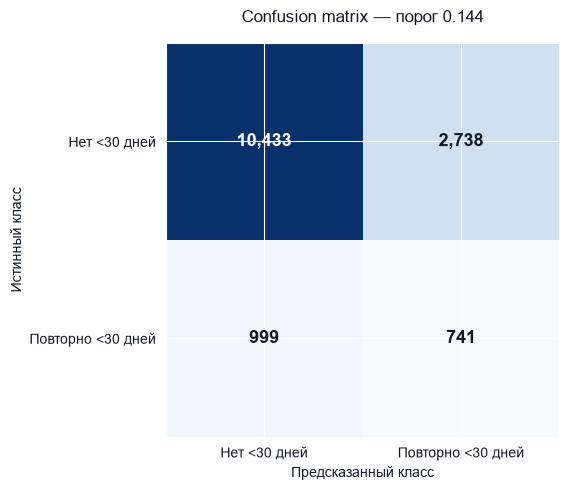

In [50]:
validation_prediction_tuned = (
    validation_probability >= best_threshold
).astype(int)

print(
    classification_report(
        y_validation,
        validation_prediction_tuned,
        digits=3,
        zero_division=0,
    )
)

confusion = confusion_matrix(
    y_validation,
    validation_prediction_tuned,
)

fig, ax = plt.subplots(
    figsize=(7, 5),
    facecolor="white",
)

display = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=["Нет <30 дней", "Повторно <30 дней"],
)

display.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False,
    values_format=",d",
)


color_threshold = confusion.max() / 2

for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        text = display.text_[row, column]

        text.set_color(
            "white"
            if confusion[row, column] > color_threshold
            else "#111827"
        )
        text.set_fontsize(13)
        text.set_fontweight("bold")

ax.set_title(
    f"Confusion matrix — порог {best_threshold:.3f}",
    color="#111827",
    pad=15,
)
ax.set_xlabel("Предсказанный класс", color="#111827")
ax.set_ylabel("Истинный класс", color="#111827")
ax.tick_params(colors="#111827")
ax.set_facecolor("white")

plt.tight_layout()
plt.show()

### Вывод по confusion matrix

При пороге 0.144 модель обнаруживает 741 из 1 740 повторных госпитализаций в течение 30 дней. Recall составляет 42.6%, то есть модель находит менее половины положительных случаев и пропускает 999 пациентов.
Precision составляет 21.3%: только примерно каждый пятый пациент, отнесённый моделью к группе риска, действительно госпитализируется повторно. Это означает большое количество ложноположительных предупреждений - 2 738 случаев.

Будем максимизировать recall

Зафиксируем полученные значения baseline

In [54]:
tn, fp, fn, tp = confusion_matrix(
    y_validation,
    validation_prediction_tuned,
).ravel()

baseline_cv = cv_results.loc["Logistic"]

In [60]:
# Все метрики baseline
baseline_metrics = {
    "model": "LogisticRegression",

    "cross_validation": {
        "folds": 5,
        "roc_auc_mean": float(baseline_cv["roc_auc_mean"]),
        "roc_auc_std": float(baseline_cv["roc_auc_std"]),
        "average_precision_mean": float(
            baseline_cv["pr_auc_mean"]
        ),
        "average_precision_std": float(
            baseline_cv["pr_auc_std"]
        ),
    },

    "validation": {
        "threshold": float(best_threshold),

        "roc_auc": float(
            roc_auc_score(
                y_validation,
                validation_probability,
            )
        ),

        "average_precision": float(
            average_precision_score(
                y_validation,
                validation_probability,
            )
        ),

        "precision": float(
            precision_score(
                y_validation,
                validation_prediction_tuned,
            )
        ),

        "recall": float(
            recall_score(
                y_validation,
                validation_prediction_tuned,
            )
        ),

        "f1": float(
            f1_score(
                y_validation,
                validation_prediction_tuned,
            )
        ),

        "accuracy": float(
            accuracy_score(
                y_validation,
                validation_prediction_tuned,
            )
        ),

        "specificity": float(
            tn / (tn + fp)
        ),

        "npv": float(
            tn / (tn + fn)
        ),

        "confusion_matrix": {
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
            "tp": int(tp),
        },
    },
}

baseline_metrics

{'model': 'LogisticRegression',
 'cross_validation': {'folds': 5,
  'roc_auc_mean': 0.649,
  'roc_auc_std': 0.007,
  'average_precision_mean': 0.208,
  'average_precision_std': 0.008},
 'validation': {'threshold': 0.14411772663327302,
  'roc_auc': 0.6592376843238846,
  'average_precision': 0.22618361700025152,
  'precision': 0.2129922391491808,
  'recall': 0.42586206896551726,
  'f1': 0.2839624449128185,
  'accuracy': 0.749379652605459,
  'specificity': 0.7921190494267709,
  'npv': 0.9126137158852344,
  'confusion_matrix': {'tn': 10433, 'fp': 2738, 'fn': 999, 'tp': 741}}}

In [64]:
metrics_path = (
    project_root
    / "reports"
    / "metrics"
    / "logistic_baseline.json"
)

metrics_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

with metrics_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        baseline_metrics,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(f"Метрики: {metrics_path}")

In [66]:
model_path = (
    project_root
    / "models"
    / "logistic_baseline.joblib"
)

model_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

baseline_artifact = {
    "pipeline": selected_model,
    "threshold": float(best_threshold),
    "feature_columns": X_train.columns.tolist(),
}

joblib.dump(
    baseline_artifact,
    model_path,
)

print(f"Модель:  {model_path}")

Метрики: /Users/mac/PycharmProjects/hospital-readmission-ml/reports/metrics/logistic_baseline.json
Модель:  /Users/mac/PycharmProjects/hospital-readmission-ml/models/logistic_baseline.joblib
